# Семинар 2. Pipeline, spaCy и Hugging Face Datasets

На прошлом семинаре мы познакомились с базовым NLP-pipeline:

```text
текст → preprocessing → TF-IDF → Logistic Regression
```

Теперь перейдём к новым инструментам и более профессиональной организации NLP-эксперимента.

### План семинара

1. **`sklearn.Pipeline`**
   - зачем объединять preprocessing и модель;
   - как Pipeline помогает избежать ошибок;
   - cross-validation;
   - `GridSearchCV`;
   - подбор гиперпараметров.

2. **spaCy**
   - `nlp`, `Doc`, `Token`, `Span`;
   - леммы и части речи;
   - синтаксические зависимости;
   - Named Entity Recognition.

3. **Hugging Face Datasets**
   - загрузка датасетов;
   - splits;
   - `Dataset`;
   - `IterableDataset`;
   - streaming.

> Главная цель семинара — перейти от отдельных операций над текстом к более цельному и воспроизводимому NLP workflow.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score
from threadpoolctl import threadpool_limits

RANDOM_STATE = 42
threadpool_limits(limits=2)


## Данные для примеров

Локальные CSV лежат в папке data и содержат заголовки столбцов.
Для демонстрационного перебора берём стратифицированную выборку из 5000 твитов.
В домашнем задании используем полный корпус.


In [2]:
def load_rutweet(path, target):
    frame = pd.read_csv(path, usecols=['ttext']).rename(columns={'ttext': 'text'})
    return frame.assign(positive=target)

positive = load_rutweet('data/positive.csv', 1)
negative = load_rutweet('data/negative.csv', 0)
rutweets = pd.concat([positive, negative], ignore_index=True)
rutweets = rutweets.dropna(subset=['text']).drop_duplicates('text').reset_index(drop=True)
data, _ = train_test_split(
    rutweets, train_size=5000, stratify=rutweets['positive'], random_state=RANDOM_STATE
)
X_train, X_test, y_train, y_test = train_test_split(
    data['text'], data['positive'], test_size=0.2,
    random_state=RANDOM_STATE, stratify=data['positive']
)
print('Train:', X_train.shape)
print('Test:', X_test.shape)


Train: (4000,)
Test: (1000,)


## 1. Зачем нужен Pipeline?

До сих пор мы писали:

```python
tfidf.fit_transform(X_train)
model.fit(...)
tfidf.transform(X_test)
model.predict(...)

TRAIN:
fit → transform → fit model

TEST:
transform → predict
```

Это полезно для понимания механики.

Но в реальном ML-проекте появляется риск:

- случайно сделать `fit` на test;
- применить разные преобразования к train и test;
- запутаться при cross-validation; - Вопрос что это такое?
- забыть один из шагов при inference.

`Pipeline` объединяет преобразования и модель в **один объект**.

In [3]:
from sklearn.pipeline import Pipeline


classifier = Pipeline([
    (
        'vectorizer',
        TfidfVectorizer(min_df=2)
    ),
    (
        'model',
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

classifier

,steps,"[('vectorizer', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


Теперь весь процесс выглядит так:

```text
raw text
   ↓
TfidfVectorizer
   ↓
LogisticRegression
```

И снаружи мы работаем с ним как с обычной моделью.

In [4]:
classifier.fit(X_train, y_train)

pipeline_pred = classifier.predict(X_test)

print(
    'F1:',
    round(f1_score(y_test, pipeline_pred, average='macro'), 4)
)

F1: 0.6794


## 2. Cross-validation

Кросс-валидация — это несколько внутренних проверок на train-данных.

Один train/test split зависит от конкретного разбиения данных.

Cross-validation несколько раз меняет validation-часть:

```text
Fold 1: train train train train | valid
Fold 2: train train train valid | train
Fold 3: train train valid train | train
...
```
```text
Допустим, у нас есть 12 объектов.

Fold 1: [1 2 3 4]       → validation
        [5 6 7 8 9 10 11 12] → train

Fold 2: [5 6 7 8]       → validation
        остальные       → train

Fold 3: [9 10 11 12]    → validation
        остальные       → train
```
В результате мы получаем более устойчивую оценку качества.

In [5]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    classifier,
    X_train,
    y_train,
    scoring='f1_macro',
    cv=3,
    n_jobs=2
)

print('F1 по folds:', cv_scores.round(4))
print('Средний F1:', round(cv_scores.mean(), 4))
print('Std:', round(cv_scores.std(), 4))

F1 по folds: [0.6566 0.6457 0.6669]
Средний F1: 0.6564
Std: 0.0087


### Зачем смотреть стандартное отклонение?

Две модели могут иметь одинаковый средний F1:

```text
Model 1: 0.91 ± 0.01
Model 2: 0.91 ± 0.08
```

Но первая модель работает значительно **стабильнее** на разных разбиениях.

## 3. GridSearchCV

**GridSearchCV - Метод автоматического подбора гиперпараметров модели, который перебирает заданные комбинации параметров и оценивает каждую из них с помощью cross-validation.**


У модели и preprocessing есть гиперпараметры.

Например:

### `TfidfVectorizer`

- `ngram_range` — какие n-граммы использовать.  
  `(1, 1)` — только отдельные слова, `(1, 2)` — слова + пары слов.

- `min_df` — минимальное количество документов, в которых должен встретиться термин, чтобы попасть в словарь.  
  Помогает убрать очень редкие слова.

- `max_df` — максимальная доля документов, в которых может встречаться термин.  
  Помогает убрать слишком частые, малоинформативные слова.

### `LogisticRegression`

- `C` — обратная сила регуляризации.  
  Чем меньше `C`, тем сильнее регуляризация.

- `penalty` — тип регуляризации: например `l1` или `l2`.

- `solver` — алгоритм оптимизации, который ищет веса модели.

### Важный момент про `C`

В `LogisticRegression`:

```text
маленький C → сильнее регуляризация
большой C   → слабее регуляризация
```

Регуляризация ограничивает слишком большие коэффициенты модели и помогает бороться с переобучением.

In [6]:
from sklearn.model_selection import GridSearchCV

grid_pipeline = Pipeline([
    (
        'vectorizer',
        TfidfVectorizer(min_df=2)
    ),
    (
        'model',
        LogisticRegression(
            solver='liblinear',
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

param_grid = {
    'vectorizer__ngram_range': [
        (1, 1),
        (1, 2)
    ],
    'model__C': [
        0.3,
        1.0,
        3.0
    ],
    'model__penalty': [
        'l1',
        'l2'
    ]
}

grid = GridSearchCV(
    estimator=grid_pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=3,
    n_jobs=2,
    verbose=1,
    refit=True
)

> На учебном ноутбуке grid специально небольшой.

В реальном проекте не стоит бездумно запускать огромный перебор: - Кто скажет почему?

```text
10 параметров × 10 значений × 5 folds
```


In [7]:
grid.fit(X_train, y_train)

print('Лучшие параметры:')
print(grid.best_params_)

print('\nЛучший CV F1:')
print(round(grid.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits


Лучшие параметры:
{'model__C': 0.3, 'model__penalty': 'l2', 'vectorizer__ngram_range': (1, 2)}

Лучший CV F1:
0.6595


Проверяем выбранную по CV модель на тестовой выборке.

In [8]:
best_pred = grid.best_estimator_.predict(X_test)

print(
    'Test F1:',
    round(f1_score(y_test, best_pred, average='macro'), 4)
)

Test F1: 0.6747


### Задание

Попробуйте добавить в `param_grid`:

```python
'vectorizer__min_df': [1, 2, 5]
```

Ответьте:

1. какой набор параметров оказался лучшим;
2. насколько изменился F1;
3. стоит ли усложнение модели полученного прироста?

#### Решение

In [9]:
param_grid_min_df = {
    'vectorizer__ngram_range': [(1, 1), (1, 2)],
    'vectorizer__min_df': [1, 2, 5],
    'model__C': [0.3, 1.0, 3.0],
    'model__penalty': ['l1', 'l2'],
}

grid_min_df = GridSearchCV(
    estimator=grid_pipeline,
    param_grid=param_grid_min_df,
    scoring='f1_macro',
    cv=3,
    n_jobs=2,
    verbose=1,
    refit=True
)
grid_min_df.fit(X_train, y_train)

pred_min_df = grid_min_df.best_estimator_.predict(X_test)
f1_min_df = f1_score(y_test, pred_min_df, average='macro')

print('1. Лучшие параметры:', grid_min_df.best_params_)
print('2. CV F1 было:', round(grid.best_score_, 4),
      '| стало:', round(grid_min_df.best_score_, 4),
      '| дельта:', round(grid_min_df.best_score_ - grid.best_score_, 4))
print('   Test F1 стало:', round(f1_min_df, 4))
print('   Дельта Test F1:', round(f1_min_df - f1_score(y_test, best_pred, average='macro'), 4))


Fitting 3 folds for each of 36 candidates, totalling 108 fits


1. Лучшие параметры: {'model__C': 3.0, 'model__penalty': 'l2', 'vectorizer__min_df': 1, 'vectorizer__ngram_range': (1, 1)}
2. CV F1 было: 0.6595 | стало: 0.6647 | дельта: 0.0052
   Test F1 стало: 0.6796
   Дельта Test F1: 0.0049


---
# Часть 2. spaCy: текст как структурированный объект

До сих пор мы в основном работали с текстом как со строкой:

```python
"Я люблю обработку естественного языка"
```

Но в NLP часто нужно знать больше:

- где находятся токены;
- какая у слова лемма;
- какая часть речи;
- от какого слова оно зависит;
- является ли фрагмент именованной сущностью.

Для таких задач удобно использовать **spaCy**.

bcdfffe5c0b9f221a2f6607f96ca0e4a.svg




## 4. Локальный запуск spaCy

Перед первым запуском выполните uv sync в папке проекта и выберите ядро из .venv.
Зависимости и русская модель spaCy уже описаны в pyproject.toml.
Для загрузки датасетов при первом запуске нужен интернет.


In [10]:
from importlib.metadata import version

print('spaCy:', version('spacy'))
print('Русская модель:', version('ru-core-news-sm'))

spaCy: 3.8.16
Русская модель: 3.8.0


Продолжаем пример и выводим результат текущего шага.

In [11]:
import spacy

nlp = spacy.load('ru_core_news_sm')

print(nlp.pipe_names)

['tok2vec', 'morphologizer', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


## 5. `nlp` и `Doc`

`nlp` — объект, который содержит pipeline обработки текста.

Передаём ему строку:

```python
doc = nlp(text)
```

и получаем объект `Doc`.

In [12]:
doc = nlp(
    'Студенты изучают обработку естественного языка в университете.'
)

print(type(doc))

for token in doc:
    print(token.text)

<class 'spacy.tokens.doc.Doc'>
Студенты
изучают
обработку
естественного
языка
в
университете
.


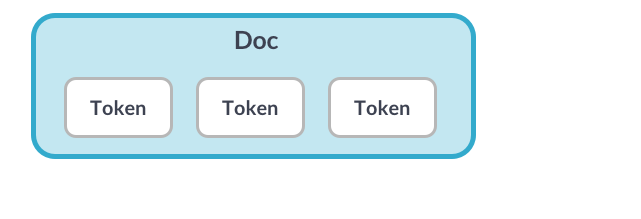

## 6. `Token`

`Doc` можно представить как последовательность токенов.

Каждый `Token` содержит не только текст слова, но и множество дополнительных атрибутов.

In [13]:
token = doc[0]

print('text      =', token.text)
print('lemma     =', token.lemma_)
print('POS       =', token.pos_)
print('is_alpha  =', token.is_alpha)
print('is_punct  =', token.is_punct)
print('like_num  =', token.like_num)

text      = Студенты
lemma     = студент
POS       = NOUN
is_alpha  = True
is_punct  = False
like_num  = False


### Что означают атрибуты `Token`

- `token.text` — исходный текст токена.
- `token.lemma_` — лемма, то есть нормальная форма слова.
- `token.pos_` — часть речи: существительное, глагол, прилагательное и т.д.
- `token.is_alpha` — состоит ли токен только из букв.
- `token.is_punct` — является ли токен знаком пунктуации.
- `token.like_num` — похож ли токен на число.

### Задание

Выведите для каждого токена:

```text
text
lemma_
pos_
is_stop
```

Какие слова spaCy считает стоп-словами?

#### Решение

In [14]:
# ваш код
print(doc)
print('=====')

for token in doc:
    print(
        token.text,
        token.lemma_,
        token.pos_,
        token.is_stop,
    )

print(
    "Стоп-слова:",
    [token.text for token in doc if token.is_stop],
)

Студенты изучают обработку естественного языка в университете.
=====
Студенты студент NOUN False
изучают изучать VERB False
обработку обработка NOUN False
естественного естественный ADJ False
языка язык NOUN False
в в ADP True
университете университет NOUN False
. . PUNCT False
Стоп-слова: ['в']


## 7. `Span`

`Span` — это срез `Doc`, содержащий несколько токенов.

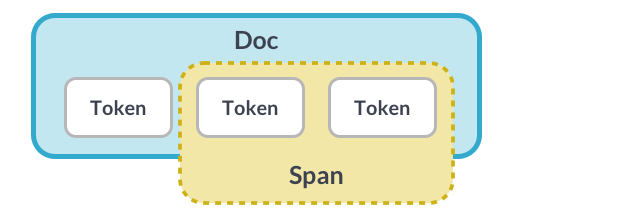

In [15]:
span = doc[2:5]

print(span.text)
print(type(span))

обработку естественного языка
<class 'spacy.tokens.span.Span'>


## 8. Лемматизация и части речи

В первом семинаре мы использовали отдельный инструмент для лемматизации.

spaCy позволяет одновременно получить:

```text
токен → лемма → часть речи
```

In [16]:
doc = nlp(
    'Красивые машины быстро ехали по заснеженной дороге.'
)

for token in doc:
    print(
        f'{token.text:15}',
        f'{token.lemma_:15}',
        token.pos_
    )

Красивые        красивый        ADJ
машины          машина          NOUN
быстро          быстро          ADV
ехали           ехать           VERB
по              по              ADP
заснеженной     заснеженной     VERB
дороге          дорога          NOUN
.               .               PUNCT


### Основные значения `POS`

1. `NOUN` — существительное  
2. `VERB` — глагол  
3. `ADJ` — прилагательное  
4. `ADV` — наречие  
5. `PRON` — местоимение  
6. `PROPN` — имя собственное  
7. `NUM` — числительное  
8. `PUNCT` — пунктуация

## 9. Синтаксические зависимости

`dep_` показывает синтаксическое отношение слова.

`head` — слово, от которого текущий токен зависит.

In [17]:
doc = nlp(
    'Студенты внимательно слушают преподавателя.'
)

for token in doc:
    print(
        token.text,
        '→',
        token.dep_,
        '→ head:',
        token.head.text
    )

Студенты → nsubj → head: слушают
внимательно → advmod → head: слушают
слушают → ROOT → head: слушают
преподавателя → obj → head: слушают
. → punct → head: слушают


## Шпаргалка: `POS` и `dep_` в spaCy

### Части речи — `token.pos_`

| Обозначение | Значение | Пример |
|---|---|---|
| `NOUN` | существительное | `студент`, `машина` |
| `VERB` | глагол | `слушать`, `ехать` |
| `ADJ` | прилагательное | `красивый`, `быстрый` |
| `ADV` | наречие | `внимательно`, `быстро` |
| `PRON` | местоимение | `я`, `он`, `они` |
| `PROPN` | имя собственное | `Москва`, `Яндекс` |
| `NUM` | числительное | `один`, `12` |
| `PUNCT` | пунктуация | `.`, `,`, `!` |

---

### Синтаксические зависимости — `token.dep_`

| Обозначение | Значение | Пример |
|---|---|---|
| `ROOT` | главное слово предложения | `слушают` |
| `nsubj` | подлежащее | `Студенты → слушают` |
| `obj` | дополнение | `преподавателя → слушают` |
| `advmod` | обстоятельство / наречный модификатор | `внимательно → слушают` |
| `amod` | определение-прилагательное | `красивый → дом` |
| `nmod` | именная модификация | `студента → книга` |
| `obl` | обстоятельственное дополнение | `в Москву → ехать` |
| `case` | предлог / показатель падежной связи | `в → Москву` |
| `conj` | однородный член | `кофе → чай` |
| `cc` | сочинительный союз | `и`, `или`, `но` |
| `aux` | вспомогательный глагол | вспомогательная глагольная форма |
| `cop` | глагол-связка | `быть`, `являться` |
| `mark` | подчинительный союз | `что`, `если`, `когда` |
| `punct` | знак пунктуации | `.`, `,`, `!` |
| `xcomp` | зависимая конструкция без собственного подлежащего | `хочу работать` |
| `ccomp` | придаточная часть с собственным подлежащим | `знаю, что он придёт` |

> `token.pos_` отвечает на вопрос **«какая это часть речи?»**  
> `token.dep_` отвечает на вопрос **«какую синтаксическую роль этот токен играет?»**  
> `token.head` показывает, **от какого слова он зависит**.

In [18]:
from spacy import displacy

displacy.render(
    doc,
    style='dep',
    jupyter=True
)

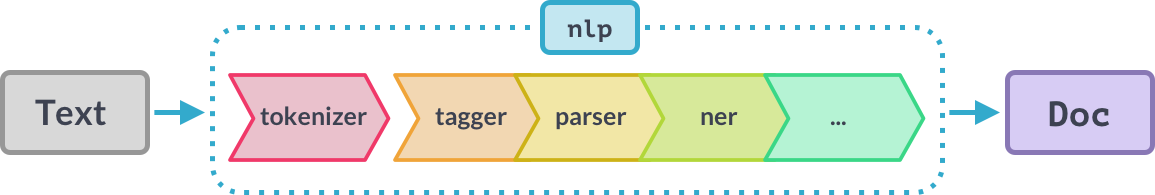

## 10. Named Entity Recognition

NER — задача поиска сущностей в тексте.

Например:

```text
Москва      → LOC
Александр   → PER
Сбербанк    → ORG
```

In [19]:
doc = nlp(
    'Александр приехал из Москвы и устроился работать в Яндекс.'
)

for ent in doc.ents:
    print(
        ent.text,
        ent.label_,
        spacy.explain(ent.label_)
    )

Александр PER Named person or family.
Москвы LOC Non-GPE locations, mountain ranges, bodies of water
Яндекс ORG Companies, agencies, institutions, etc.


Показываем найденные сущности в тексте.

In [20]:
displacy.render(
    doc,
    style='ent',
    jupyter=True
)

### Задание

Возьмите любое короткое новостное предложение и:

1. найдите все токены;
2. выведите леммы;
3. выведите части речи;
4. найдите именованные сущности;
5. визуализируйте зависимости.

#### Решение

In [21]:
# Ваше решение
# Ваше решение
from spacy import displacy

# Короткое новостное предложение
text = "Компания Яндекс открыла новый офис в Москве."

# Обрабатываем текст с помощью spaCy
doc = nlp(text)

# 1. Токены
print("Токены:")
print([token.text for token in doc])

# 2. Леммы
print("\nЛеммы:")
print([token.lemma_ for token in doc])

# 3. Части речи
print("\nЧасти речи:")
for token in doc:
    print(f"{token.text:<10} -> {token.pos_}")

# 4. Именованные сущности
print("\nИменованные сущности:")
for ent in doc.ents:
    print(f"{ent.text:<10} -> {ent.label_}")

# 5. Визуализация синтаксических зависимостей
displacy.render(doc, style="dep", jupyter=True)

Токены:
['Компания', 'Яндекс', 'открыла', 'новый', 'офис', 'в', 'Москве', '.']

Леммы:
['компания', 'яндекс', 'открыть', 'новый', 'офис', 'в', 'москва', '.']

Части речи:
Компания   -> NOUN
Яндекс     -> PROPN
открыла    -> VERB
новый      -> ADJ
офис       -> NOUN
в          -> ADP
Москве     -> PROPN
.          -> PUNCT

Именованные сущности:
Яндекс     -> ORG
Москве     -> LOC


### Что важно понять про spaCy

spaCy не заменяет TF-IDF или классификатор.

Это другой уровень NLP-инструментария.


TF-IDF
→ статистическая мера, которая показывает, насколько важно слово для конкретного документа внутри большого набора документов (корпуса). Знание меры позволяет базово векторизвать текст

spaCy
→ структурированный лингвистический анализ текста в котором учитывается не только частота, а так же морфологический, лингвистический анализ и взаимосвязи слов в тексте


В реальном проекте эти подходы могут использоваться вместе.
### Список типов именованных сущностей

Полное описание Named Entity Recognition и основных типов сущностей можно посмотреть в официальной документации spaCy:

[spaCy — Named Entity Recognition](https://spacy.io/usage/linguistic-features#named-entities)

Например:

- `PER` / `PERSON` — человек;
- `ORG` — организация;
- `LOC` — географическая локация;
- `GPE` — страна, город, регион;
- `MONEY` — денежное значение;
- `DATE` — дата;
- `TIME` — время.

> Набор доступных `label` зависит от конкретной языковой модели spaCy.

---
# Часть 3. Hugging Face Datasets

# Hugging Face Datasets

Официальная документация библиотеки:

[Hugging Face Datasets — Documentation](https://huggingface.co/docs/datasets/index)

Полезные разделы:

- [Loading datasets](https://huggingface.co/docs/datasets/loading)
- [Dataset object](https://huggingface.co/docs/datasets/package_reference/main_classes#datasets.Dataset)
- [Streaming](https://huggingface.co/docs/datasets/stream)

## 11. Зачем Hugging Face?

До сих пор датасеты лежали у нас локально:

```text
positive.csv
negative.csv
```

Но в ML существует большое количество публичных датасетов и моделей.

**Hugging Face** — одна из основных платформ современной NLP/ML-экосистемы.

Библиотека `datasets` позволяет:

- находить и загружать датасеты;
- работать со splits-отдельные части тренировочной/валидационной/тестовой выборки;
- быстро применять преобразования;
- читать большие датасеты потоково.

In [22]:
print('datasets:', version('datasets'))

datasets: 5.1.0


## 12. Смотрим описание датасета до загрузки

In [23]:
from datasets import load_dataset_builder

builder = load_dataset_builder(
    'cornell-movie-review-data/rotten_tomatoes'
)

print(builder.info.description[:1000])
print(builder.info.features)


{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}


## 13. Загружаем Dataset

In [24]:
from datasets import load_dataset

dataset = load_dataset(
    'cornell-movie-review-data/rotten_tomatoes',
    split='train'
)

dataset

Generating train split:   0%|          | 0/8530 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label'],
    num_rows: 8530
})

Смотрим одну запись загруженного датасета.

In [25]:
dataset[0]

{'text': 'the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .',
 'label': 1}

Смотрим первые три записи датасета.

In [26]:
dataset[:3]

{'text': ['the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .',
  'the gorgeously elaborate continuation of " the lord of the rings " trilogy is so huge that a column of words cannot adequately describe co-writer/director peter jackson\'s expanded vision of j . r . r . tolkien\'s middle-earth .',
  'effective but too-tepid biopic'],
 'label': [1, 1, 1]}

`Dataset` похож на таблицу, но оптимизирован для ML-задач.

Можно получать:

- отдельную строку;
- срез;
- столбец;
- применять преобразования через `.map()`.

## 14. Splits

У ML-датасета часто уже есть:

```text
train
validation
test
```

In [27]:
from datasets import get_dataset_split_names

get_dataset_split_names('cornell-movie-review-data/rotten_tomatoes')

['train', 'validation', 'test']

### Почему готовые splits полезны?

Если авторы датасета заранее зафиксировали train/test:

- эксперименты разных людей легче сравнивать;
- уменьшается вероятность случайно получить «удобное» разбиение;
- benchmark становится воспроизводимым.

## 15. Dataset → pandas

In [28]:
small_dataset = dataset.select(range(100))

df_hf = small_dataset.to_pandas()

df_hf.head()

,text,label
0,the rock is destined to be the 21st century's ...,1
1,"the gorgeously elaborate continuation of "" the...",1
2,effective but too-tepid biopic,1
3,if you sometimes like to go to the movies to h...,1
4,"emerges as something rare , an issue movie tha...",1


То есть Hugging Face Datasets не отменяет привычный `pandas`.

Обычно мы выбираем инструмент под задачу:

```text
pandas
→ табличный анализ и EDA

datasets.Dataset
→ ML/NLP pipeline и большие наборы данных
```

## 16. `IterableDataset`

Обычный `Dataset` предоставляет произвольный доступ:

```python
dataset[100]
```

Но очень большой датасет может не помещаться в память.

Тогда используется потоковая обработка:

```text
данные → по одному объекту → обработка
```

In [29]:
iterable_dataset = dataset.to_iterable_dataset()

first_three = list(iterable_dataset.take(3))

first_three

[{'text': 'the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .',
  'label': 1},
 {'text': 'the gorgeously elaborate continuation of " the lord of the rings " trilogy is so huge that a column of words cannot adequately describe co-writer/director peter jackson\'s expanded vision of j . r . r . tolkien\'s middle-earth .',
  'label': 1},
 {'text': 'effective but too-tepid biopic', 'label': 1}]

В реальном streaming-сценарии датасет можно читать с удалённого источника, не загружая его полностью.

Это особенно полезно для:

- больших корпусов;
- обучения language models;
- пайплайнов, где данные обрабатываются последовательно.

### Задание

Для любого другого датасета из пространства Hugging Face:

1. получите список доступных splits;
2. загрузите `test`;
3. выведите 5 случайных текстов;
4. посмотрите распределение `label`;


#### Решение

Получаем splits другого датасета. Используем русскоязычные новости Russian_sentiment. Семантика числовых меток не описана в карточке, поэтому сохраняем названия класс 0 и класс 1.

In [30]:
HF_DATASET = 'sepidmnorozy/Russian_sentiment'
HF_REVISION = '425782737526786fdb69a9e799e22b1d3b29da3b'
print(get_dataset_split_names(HF_DATASET, revision=HF_REVISION))

['train', 'validation', 'test']


Загружаем test и выводим пять случайных текстов с фиксированным seed.

In [31]:
news_test_dataset = load_dataset(HF_DATASET, split='test', revision=HF_REVISION)
for row in news_test_dataset.shuffle(seed=RANDOM_STATE).select(range(5)):
    print('Класс:', row['label'])
    print(row['text'])
    print()

Класс: 1
Официальный дилер марок Nissan , Mitsubishi , Mercedes - Benz , Subaru и Jeep международный автомобильный холдинг ASTER AUTO разработал программу ASTER Finance , которая в сущности является адаптированным для физических лиц лизингом.Как отметил исполнительный директор компании Аскар Бурунчин , в условиях девальвации при обратном выкупе автомобиль может быть оценен выше своей первоначальной стоимости . Кроме того , у клиента всегда есть выбор : по прошествии 3 - х лет выкупить авто , погасив кредит , обменять его на новый автомобиль или вернуть вернуть автоцентру . Единственное условие - правильная эксплуатация.Если подробнее , то суть программы заключается в снижении суммы первого взноса ( от 10 % ) , минимизация ежемесячных платежей и минимизация рисков в случае невозможности или неактуальности продолжать выплачивать кредит . Это достигается благодаря программе обратного выкупа финансируемых авто . Таким образом , клиенты могут не беспокоится - в случае непредвиденных обстоят

Смотрим число объектов и долю каждого класса в test.

In [32]:
test_labels = pd.Series(news_test_dataset['label'])
display(pd.DataFrame({
    'count': test_labels.value_counts().sort_index(),
    'share': test_labels.value_counts(normalize=True).sort_index()
}))

,count,share
0,285,0.32872
1,582,0.67128


# Работа на дом

### Задание 1. Улучшите baseline

Для RuTweetCorp соберите `Pipeline`:

```text
TfidfVectorizer → LogisticRegression
```
Разделите признаки при preprocessing

Разделите признаки на два блока:

- **текстовые** → слова и n-граммы → `TF-IDF`;
- **эмоциональные** → смайлики, скобки, `!`, `?`, CAPS, повторяющаяся пунктуация.

Эмоциональные признаки представьте отдельно как числовые значения и масштабируйте, например через `MaxAbsScaler`.

После этого объедините оба блока:

```text
TF-IDF текста
+
масштабированные emotion-features
→ LogisticRegression

Дополнительно попробуйте несколько весов эмоционального блока, например:
0.1 / 0.3 / 0.5 / 1.0

и выберите значение по cross-validation.
Цель — не удалить эмоциональные признаки, но и не позволить модели полностью опираться только на них.
```

и сравните минимум 3 конфигурации при обучении.

Попробуйте менять:

- `ngram_range`;
- `min_df`;
- `C`.

Для каждого эксперимента сохраните:

- CV F1;
- test F1;
- параметры.

В конце укажите:

- лучшие найденные гиперпараметры;
- лучший CV F1;
- F1 на test;
- короткий вывод о том, что изменилось относительно baseline из первой лабораторной.

---

#### Решение задания 1. Улучшение baseline RuTweetCorp

Готовим полный корпус так же, как в первой работе. Очищаем и лемматизируем текст с Mystem, исходный текст сохраняем для эмоциональных признаков. Это преобразование не обучается на корпусе.

In [33]:
import re
from pymystem3 import Mystem
from nltk.corpus import stopwords
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score, ParameterGrid
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

mystem = Mystem()
russian_stopwords = stopwords.words('russian')

def preprocess_text(text):
    cleaned = ' '.join(re.sub(r'[^а-яё ]', ' ', text.lower()).split())
    return ' '.join(''.join(mystem.lemmatize(cleaned)).split())

tweet_data = rutweets.copy()
tweet_data['lemm_text'] = tweet_data['text'].apply(preprocess_text)
print('Полный корпус:', tweet_data.shape)
display(tweet_data.head())

Полный корпус: (217440, 3)


,text,positive,lemm_text
0,"@first_timee хоть я и школота, но поверь, у на...",1,хоть я и школоть но поверять у мы то же самый ...
1,"Да, все-таки он немного похож на него. Но мой ...",1,да весь таки он немного похожий на он но мой м...
2,RT @KatiaCheh: Ну ты идиотка) я испугалась за ...,1,ну ты идиотка я испугаться за ты
3,"RT @digger2912: ""Кто то в углу сидит и погибае...",1,кто то в угол сидеть и погибать от голод а мы ...
4,@irina_dyshkant Вот что значит страшилка :D\nН...,1,вот что значить страшилка но блин посмотреть в...


Повторяем стратифицированное разбиение первой работы. Для всех экспериментов фиксируем одинаковые три фолда и используем macro F1, чтобы одинаково учитывать оба класса.

In [34]:
tweet_train, tweet_test, tweet_y_train, tweet_y_test = train_test_split(
    tweet_data[['text', 'lemm_text']], tweet_data['positive'],
    test_size=0.2, random_state=RANDOM_STATE, stratify=tweet_data['positive']
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
display(pd.DataFrame({
    'train': tweet_y_train.value_counts(), 'test': tweet_y_test.value_counts()
}).sort_index())

,train,test
positive,,
0,85635,21409
1,88317,22079


Воспроизводим baseline первой работы и дополнительно измеряем CV F1. TF-IDF обучается заново внутри каждого фолда.

In [35]:
tweet_baseline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words=russian_stopwords, min_df=2, max_df=0.95, max_features=100000
    )),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
baseline_cv = cross_val_score(
    tweet_baseline, tweet_train['lemm_text'], tweet_y_train,
    scoring='f1_macro', cv=cv, n_jobs=2
)
print('Baseline CV F1:', baseline_cv.mean().round(4))
print('Std:', baseline_cv.std().round(4))

Baseline CV F1: 0.707
Std: 0.0005


Считаем смайлики, скобки, восклицательные и вопросительные знаки, слова в CAPS и серии пунктуации. Признаки извлекаются из исходного текста до очистки.

In [36]:
emotion_names = ['smile', 'sad', 'open_bracket', 'close_bracket',
                 'exclamation', 'question', 'caps_words', 'caps_share', 'repeated_punct']

def emotion_features(texts):
    rows = []
    for text in texts:
        letters = [char for char in text if char.isalpha()]
        words = re.findall(r'[A-Za-zА-Яа-яЁё]+', text)
        rows.append([
            len(re.findall(r'[:;=8][-^]?[)DРPpрd]', text)),
            len(re.findall(r'[:;=8][-^]?[(]', text)),
            text.count('('), text.count(')'), text.count('!'), text.count('?'),
            sum(len(word) > 1 and word.isupper() for word in words),
            sum(char.isupper() for char in letters) / max(len(letters), 1),
            len(re.findall(r'[!?.,:;()]{2,}', text))
        ])
    return np.asarray(rows, dtype=float)

display(pd.DataFrame(emotion_features(tweet_train['text'].head()), columns=emotion_names))

,smile,sad,open_bracket,close_bracket,exclamation,question,caps_words,caps_share,repeated_punct
0,0.0,0.0,2.0,0.0,0.0,0.0,3.0,0.095238,1.0
1,0.0,0.0,5.0,0.0,0.0,0.0,3.0,0.250000,2.0
2,2.0,0.0,0.0,6.0,0.0,1.0,0.0,0.025974,3.0
3,0.0,1.0,3.0,0.0,0.0,0.0,0.0,0.012346,1.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.024691,0.0


Объединяем лемматизированный текст и эмоциональный блок через ColumnTransformer. Масштабирование обучается только на train каждого фолда, вес применяется после масштабирования.

In [37]:
tweet_features = ColumnTransformer([
    ('text', TfidfVectorizer(
        stop_words=russian_stopwords, max_df=0.95, max_features=100000
    ), 'lemm_text'),
    ('emotion', Pipeline([
        ('extract', FunctionTransformer(emotion_features)),
        ('scale', MaxAbsScaler())
    ]), 'text')
], transformer_weights={'text': 1.0, 'emotion': 0.3}, sparse_threshold=1.0)

tweet_pipeline = Pipeline([
    ('features', tweet_features),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

Сравниваем три набора ngram_range, min_df и C с четырьмя весами эмоционального блока. Всего 12 конфигураций. Победителя выбираем только по среднему CV F1.

In [38]:
text_configs = [
    {'ngram_range': (1, 1), 'min_df': 2, 'C': 1.0},
    {'ngram_range': (1, 2), 'min_df': 2, 'C': 1.0},
    {'ngram_range': (1, 2), 'min_df': 5, 'C': 3.0}
]
tweet_experiments = []
for config in text_configs:
    for weight in [0.1, 0.3, 0.5, 1.0]:
        params = {
            'features__text__ngram_range': config['ngram_range'],
            'features__text__min_df': config['min_df'],
            'features__transformer_weights': {'text': 1.0, 'emotion': weight},
            'model__C': config['C']
        }
        candidate = clone(tweet_pipeline).set_params(**params)
        scores = cross_val_score(
            candidate, tweet_train, tweet_y_train, scoring='f1_macro', cv=cv, n_jobs=2
        )
        tweet_experiments.append({
            **config, 'emotion_weight': weight, 'cv_f1': scores.mean(),
            'cv_std': scores.std(), 'params': params
        })
        print(config, 'weight:', weight, 'CV F1:', round(scores.mean(), 4), flush=True)

tweet_results = pd.DataFrame(tweet_experiments).sort_values('cv_f1', ascending=False)
best_tweet_params = tweet_results.iloc[0]['params']
display(tweet_results.drop(columns='params'))

{'ngram_range': (1, 1), 'min_df': 2, 'C': 1.0} weight: 0.1 CV F1: 0.7741


{'ngram_range': (1, 1), 'min_df': 2, 'C': 1.0} weight: 0.3 CV F1: 0.881


{'ngram_range': (1, 1), 'min_df': 2, 'C': 1.0} weight: 0.5 CV F1: 0.9254


{'ngram_range': (1, 1), 'min_df': 2, 'C': 1.0} weight: 1.0 CV F1: 0.9709


{'ngram_range': (1, 2), 'min_df': 2, 'C': 1.0} weight: 0.1 CV F1: 0.7781


{'ngram_range': (1, 2), 'min_df': 2, 'C': 1.0} weight: 0.3 CV F1: 0.8836


... (3 outputs left out)

{'ngram_range': (1, 2), 'min_df': 5, 'C': 3.0} weight: 0.3 CV F1: 0.9097


{'ngram_range': (1, 2), 'min_df': 5, 'C': 3.0} weight: 0.5 CV F1: 0.9472


{'ngram_range': (1, 2), 'min_df': 5, 'C': 3.0} weight: 1.0 CV F1: 0.9805


,ngram_range,min_df,C,emotion_weight,cv_f1,cv_std
11,"(1, 2)",5,3.0,1.0,0.980466,0.002190
7,"(1, 2)",2,1.0,1.0,0.971256,0.003205
3,"(1, 1)",2,1.0,1.0,0.970853,0.003730
10,"(1, 2)",5,3.0,0.5,0.947154,0.004289
6,"(1, 2)",2,1.0,0.5,0.927254,0.005667
2,"(1, 1)",2,1.0,0.5,0.925415,0.006954
9,"(1, 2)",5,3.0,0.3,0.909690,0.005628
5,"(1, 2)",2,1.0,0.3,0.883572,0.005532
1,"(1, 1)",2,1.0,0.3,0.880957,0.006107
8,"(1, 2)",5,3.0,0.1,0.803535,0.004871


После выбора по CV оцениваем все конфигурации на test для отчёта. Результаты test не используются для повторного подбора параметров.

In [39]:
tweet_baseline.fit(tweet_train['lemm_text'], tweet_y_train)
baseline_prediction = tweet_baseline.predict(tweet_test['lemm_text'])
baseline_test_f1 = f1_score(tweet_y_test, baseline_prediction, average='macro')
for index, row in tweet_results.iterrows():
    candidate = clone(tweet_pipeline).set_params(**row['params'])
    candidate.fit(tweet_train, tweet_y_train)
    prediction = candidate.predict(tweet_test)
    tweet_results.loc[index, 'test_f1'] = f1_score(tweet_y_test, prediction, average='macro')

tweet_report = tweet_results.drop(columns='params')
display(tweet_report)
print('Baseline test Accuracy:', round(accuracy_score(tweet_y_test, baseline_prediction), 4))
print('Baseline test F1:', round(baseline_test_f1, 4))
print('Лучшие параметры по CV:', best_tweet_params)
best_tweet_result = tweet_results.iloc[0]
print('Лучший CV F1:', round(best_tweet_result['cv_f1'], 4))
print('Его test F1:', round(best_tweet_result['test_f1'], 4))
print('Изменение test F1 к первой работе:', round(best_tweet_result['test_f1'] - baseline_test_f1, 4))

,ngram_range,min_df,C,emotion_weight,cv_f1,cv_std,test_f1
11,"(1, 2)",5,3.0,1.0,0.980466,0.002190,0.983921
7,"(1, 2)",2,1.0,1.0,0.971256,0.003205,0.975500
3,"(1, 1)",2,1.0,1.0,0.970853,0.003730,0.975177
10,"(1, 2)",5,3.0,0.5,0.947154,0.004289,0.957437
6,"(1, 2)",2,1.0,0.5,0.927254,0.005667,0.936938
2,"(1, 1)",2,1.0,0.5,0.925415,0.006954,0.937168
9,"(1, 2)",5,3.0,0.3,0.909690,0.005628,0.921655
5,"(1, 2)",2,1.0,0.3,0.883572,0.005532,0.896532
1,"(1, 1)",2,1.0,0.3,0.880957,0.006107,0.895225
8,"(1, 2)",5,3.0,0.1,0.803535,0.004871,0.827294


Baseline test Accuracy: 0.7174
Baseline test F1: 0.7169
Лучшие параметры по CV: {'features__text__ngram_range': (1, 2), 'features__text__min_df': 5, 'features__transformer_weights': {'text': 1.0, 'emotion': 1.0}, 'model__C': 3.0}
Лучший CV F1: 0.9805
Его test F1: 0.9839
Изменение test F1 к первой работе: 0.2671


Сопоставляем веса эмоционального блока по CV.

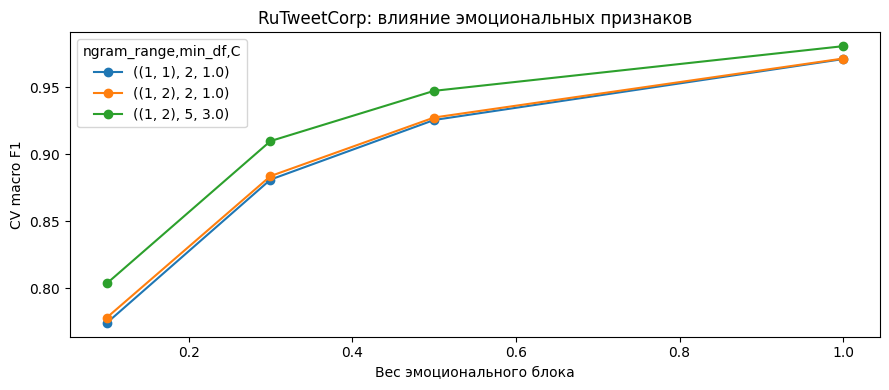

In [40]:
tweet_results.pivot_table(
    index='emotion_weight', columns=['ngram_range', 'min_df', 'C'], values='cv_f1'
).plot(marker='o', figsize=(9, 4))
plt.ylabel('CV macro F1')
plt.xlabel('Вес эмоционального блока')
plt.title('RuTweetCorp: влияние эмоциональных признаков')
plt.tight_layout()
plt.show()

### Задание 2. Анализ нового датасета с помощью spaCy

Выберите любой текстовый датасет из Hugging Face Datasets.

Требования к датасету:

- должна быть текстовая колонка;
- должен быть target для задачи классификации.

Возьмите случайную выборку текстов и проведите анализ с помощью `spaCy`.

Для текстов получите:

- токены;
- леммы;
- POS;
- синтаксические зависимости;
- именованные сущности.

Дополнительно посчитайте:

- самые частые POS;
- самые частые леммы;
- количество сущностей разных типов.

Результаты желательно визуализировать.

Сделайте короткий вывод:

- какие особенности текстов вы обнаружили;
- какие части речи встречаются чаще всего;
- какие сущности чаще всего находит `spaCy`;
- есть ли спорные или ошибочные результаты.

---

#### Решение задания 2. Анализ русскоязычных новостей с spaCy

Используем тот же Russian_sentiment, что и в упражнении выше. Сохраняем готовые splits. Проверяем пропуски, дубли и пересечения текстов между выборками.

In [41]:
news_dataset = load_dataset(HF_DATASET, revision=HF_REVISION)
news_frames = {}
seen_texts = set()
for split in ['train', 'validation', 'test']:
    frame = news_dataset[split].to_pandas().dropna(subset=['text', 'label'])
    frame = frame[frame['text'].str.strip().ne('')].drop_duplicates('text')
    overlap = frame['text'].isin(seen_texts)
    print(split, 'пересечений с предыдущими splits:', int(overlap.sum()))
    frame = frame.loc[~overlap].reset_index(drop=True)
    news_frames[split] = frame
    seen_texts.update(frame['text'])
news_train = news_frames['train']
news_test = news_frames['test']
display(pd.DataFrame({key: value['label'].value_counts() for key, value in news_frames.items()}))

train пересечений с предыдущими splits: 0
validation пересечений с предыдущими splits: 1
test пересечений с предыдущими splits: 6


,train,validation,test
label,,,
1,1940,271,577
0,994,152,284


Для исследовательского анализа случайно выбираем 100 обучающих новостей. Тестовые тексты не используем для выбора признаков.

In [42]:
from collections import Counter

news_sample = news_train.sample(n=100, random_state=RANDOM_STATE)
sample_docs = list(nlp.pipe(news_sample['text'], batch_size=16))
token_table = pd.DataFrame([
    {'document': i, 'token': token.text, 'lemma': token.lemma_,
     'POS': token.pos_, 'dependency': token.dep_, 'head': token.head.text}
    for i, doc in enumerate(sample_docs) for token in doc if not token.is_space
])
entity_table = pd.DataFrame([
    {'document': i, 'entity': ent.text, 'type': ent.label_}
    for i, doc in enumerate(sample_docs) for ent in doc.ents
], columns=['document', 'entity', 'type'])
display(token_table.head(40))
display(entity_table.head(30))

,document,token,lemma,POS,dependency,head
0,0,Если,если,SCONJ,mark,основываться
1,0,основываться,основываться,VERB,advcl,держал
2,0,на,на,ADP,case,данных
3,0,последних,последний,ADJ,amod,данных
4,0,данных,данных,NOUN,obl,основываться
5,0,по,по,ADP,case,структуре
6,0,структуре,структура,NOUN,nmod,данных
7,0,инвестпортфеля,инвестпортфеля,NOUN,nmod,структуре
8,0,Единого,единый,ADJ,amod,фонда
9,0,накопительного,накопительный,ADJ,amod,фонда


,document,entity,type
0,0,Единого накопительного фонда ( ЕНПФ ),ORG
1,0,ЕНПФ,ORG
2,0,Казинвестбанка,LOC
3,0,Kapital.kz,ORG
4,0,Казинвестбанке,LOC
5,0,Казинвестбанке,LOC
6,0,Казкоме,LOC
7,0,ЕНПФ,ORG
8,0,ДБ ' Сбербанк ',ORG
9,0,Евразийском банке,ORG


Подсчитываем части речи, содержательные леммы и типы сущностей. Для частых лемм исключаем стоп-слова и небуквенные токены.

,count
POS,
NOUN,23192
PUNCT,13356
ADJ,9603
ADP,7600
VERB,6506
PROPN,5165
NUM,2617
ADV,2535
CCONJ,2312


,count
год,716
казахстан,346
тенге,310
развитие,285
проект,238
млрд,216
компания,202
страна,192
банк,159
рынок,154


,count
type,
ORG,1784
LOC,1249
PER,744


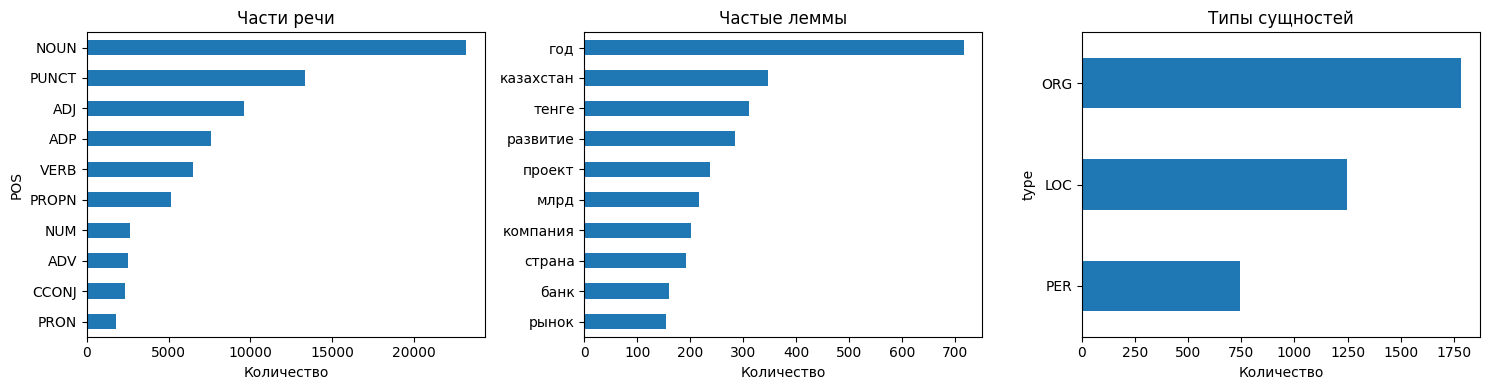

In [43]:
pos_counts = token_table['POS'].value_counts()
lemma_counts = pd.Series(Counter(
    token.lemma_.lower() for doc in sample_docs for token in doc
    if token.is_alpha and not token.is_stop
)).sort_values(ascending=False)
entity_counts = entity_table['type'].value_counts()
display(pos_counts.to_frame('count'))
display(lemma_counts.head(15).to_frame('count'))
display(entity_counts.to_frame('count'))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for series, ax, title in zip(
    [pos_counts.head(10), lemma_counts.head(10), entity_counts], axes,
    ['Части речи', 'Частые леммы', 'Типы сущностей']
):
    series.sort_values().plot.barh(ax=ax, title=title)
    ax.set_xlabel('Количество')
plt.tight_layout()
plt.show()

Визуализируем зависимости первого предложения случайного текста и сущности в его начале. Остальной анализ выполнен для полных текстов.

In [44]:
example_doc = sample_docs[0]
displacy.render(next(example_doc.sents), style='dep', jupyter=True, options={'compact': True})
displacy.render(nlp(example_doc.text[:1000]), style='ent', jupyter=True)

Смотрим контекст найденных сущностей и частые синтаксические зависимости.

In [45]:
display(token_table['dependency'].value_counts().head(10).to_frame('count'))
for doc in sample_docs[:3]:
    for ent in list(doc.ents)[:8]:
        print(ent.label_, repr(ent.text), '|', ent.sent.text[:250])

,count
dependency,
punct,13188
nmod,12011
amod,8684
case,7700
obl,4505
conj,3947
ROOT,3937
nsubj,3881
advmod,2816


ORG 'Единого накопительного фонда ( ЕНПФ )' | Если основываться на последних данных по структуре инвестпортфеля Единого накопительного фонда ( ЕНПФ ) , на 1 декабря 2016 года ЕНПФ держал часть пенсионных накоплений на депозите Казинвестбанка .
ORG 'ЕНПФ' | Если основываться на последних данных по структуре инвестпортфеля Единого накопительного фонда ( ЕНПФ ) , на 1 декабря 2016 года ЕНПФ держал часть пенсионных накоплений на депозите Казинвестбанка .
LOC 'Казинвестбанка' | Если основываться на последних данных по структуре инвестпортфеля Единого накопительного фонда ( ЕНПФ ) , на 1 декабря 2016 года ЕНПФ держал часть пенсионных накоплений на депозите Казинвестбанка .
ORG 'Kapital.kz' | Об этом сообщает корреспондент центра деловой информации Kapital.kz .
LOC 'Казинвестбанке' | ( https : / / kapital.kz / ) Так , на начало декабря в Казинвестбанке было размещено 2,9 млрд тенге — это 0,04 % всех пенсионных накоплений .
LOC 'Казинвестбанке' | Если же рассматривать структуру депозитного пор

### Задание 3. Постройте baseline для выбранного датасета

Для того же датасета соберите `Pipeline`:

```text
TfidfVectorizer → LogisticRegression
```

Используйте:

- готовые `train / test` splits из Hugging Face, если они есть;
- либо самостоятельно разделите данные.

Обучите и оцените модель по:

- Accuracy;
- Precision;
- Recall;
- F1.

Также постройте:

- confusion matrix.

В конце ответьте:

- какое качество получил baseline;
- есть ли дисбаланс классов;
- какие классы модель путает чаще всего и по какой причине;
- какие признаки, найденные через `spaCy`, потенциально могут улучшить модель.

---


Добавьте к TF-IDF признаки, полученные с помощью `spaCy`.

Например:

```text
TF-IDF
+
количество NOUN
+
количество VERB
+
доля ADJ
+
количество именованных сущностей
```

Обучите новую модель и сравните её с baseline.

Ответьте на вопрос:

```text
Улучшили ли лингвистические признаки качество модели?
```

---

#### Решение задания 3. Классификация и добавление лингвистических признаков

Обучаем TF-IDF baseline на готовом train. Стоп-слова не удаляем, чтобы сохранить отрицания. Для несбалансированной задачи выводим macro метрики и отчёт по каждому классу.

,Accuracy,Precision macro,Recall macro,F1 macro
TF-IDF,0.898955,0.917176,0.855771,0.877547


              precision    recall  f1-score   support

           0       0.95      0.73      0.83       284
           1       0.88      0.98      0.93       577

    accuracy                           0.90       861
   macro avg       0.92      0.86      0.88       861
weighted avg       0.90      0.90      0.89       861



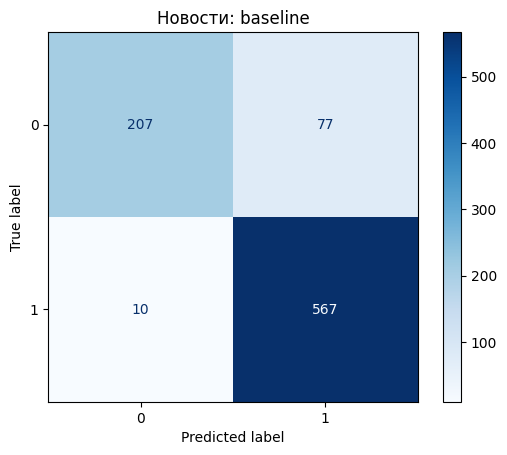

In [46]:
news_baseline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100000)),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
news_baseline.fit(news_train['text'], news_train['label'])
news_prediction = news_baseline.predict(news_test['text'])

def classification_metrics(actual, prediction):
    return {
        'Accuracy': accuracy_score(actual, prediction),
        'Precision macro': precision_score(actual, prediction, average='macro', zero_division=0),
        'Recall macro': recall_score(actual, prediction, average='macro', zero_division=0),
        'F1 macro': f1_score(actual, prediction, average='macro')
    }

news_scores = {'TF-IDF': classification_metrics(news_test['label'], news_prediction)}
display(pd.DataFrame(news_scores).T)
print(classification_report(news_test['label'], news_prediction, zero_division=0))
ConfusionMatrixDisplay.from_predictions(news_test['label'], news_prediction, cmap='Blues')
plt.title('Новости: baseline')
plt.show()

Сравниваем доли классов и выводим примеры ошибок baseline.

In [47]:
display(pd.DataFrame({
    'train': news_train['label'].value_counts(normalize=True),
    'test': news_test['label'].value_counts(normalize=True)
}).sort_index())
news_errors = news_test.assign(prediction=news_prediction)
news_errors = news_errors[news_errors['label'] != news_errors['prediction']]
display(news_errors.groupby(['label', 'prediction']).size().to_frame('count'))
for _, row in news_errors.sample(min(5, len(news_errors)), random_state=RANDOM_STATE).iterrows():
    print('Истинный класс:', row['label'], 'Предсказание:', row['prediction'])
    print(row['text'][:1200])
    print()

,train,test
label,,
0,0.338787,0.329849
1,0.661213,0.670151


,,count
label,prediction,
0,1,77
1,0,10


Истинный класс: 0 Предсказание: 1
В результате неэффективного информирования населения о прибытии специализированного медицинского поезда ' Денсаулык ' , прибывшие врачи не смогли оказать помощь местным жителям , рассказал в ходе брифинга в СЦК председатель правления АО ' Железнодорожные госпитали медицины катастроф ' КЧС МВД Габдылнур Абдильманов , передает корреспондент . ' Действительно , на станции Лепсы ( Алматинская область — прим.агенства ) поезд стоял и вовремя не было оповещено население , люди хотели , но не знали о том , что поезд есть , а врачи не смогли оказать консультативную помощь . Нами всегда заранее совместно с КЧС и ДЧС областей идет оповещение графика движения поездов , на каждой станции в какой день , в какой час и обычно этой работой занимаются местные поселковые и районные акиматы , они собирают людей с отдаленных поселков , организованно привозят их на автобусах . В этот раз о приезде поезда объявили слишком поздно ' , — пояснил Габдылнур Абдильманов.Спикер отм

Извлекаем фиксированные признаки spaCy для полных текстов: длину, числа NOUN и VERB, доли ADJ и ADV, число сущностей и количества PER, ORG и LOC. spaCy не дообучается на корпусе, поэтому признаки можно вычислить один раз до CV.

In [48]:
linguistic_columns = ['tokens', 'NOUN', 'VERB', 'ADJ_share', 'ADV_share', 'entities', 'PER', 'ORG', 'LOC']

def linguistic_features(texts):
    rows = []
    for doc in nlp.pipe(texts, batch_size=16):
        words = [token for token in doc if not token.is_punct and not token.is_space]
        pos = Counter(token.pos_ for token in words)
        entities = Counter(ent.label_ for ent in doc.ents)
        rows.append([
            len(words), pos['NOUN'], pos['VERB'],
            pos['ADJ'] / max(len(words), 1), pos['ADV'] / max(len(words), 1),
            len(doc.ents), entities['PER'], entities['ORG'], entities['LOC']
        ])
    return pd.DataFrame(rows, columns=linguistic_columns)

news_train_features = pd.concat([
    news_train[['text']], linguistic_features(news_train['text'])
], axis=1)
news_test_features = pd.concat([
    news_test[['text']], linguistic_features(news_test['text'])
], axis=1)
display(news_train_features.head())

,text,tokens,NOUN,VERB,ADJ_share,ADV_share,entities,PER,ORG,LOC
0,Досудебное расследование по факту покупки ЕНПФ...,168,56,26,0.136905,0.017857,20,3,15,2
1,Медики рассказали о состоянии пострадавшего му...,204,78,24,0.112745,0.019608,19,2,10,7
2,"Прошел почти год , как железнодорожным операто...",1128,421,149,0.107270,0.041667,43,9,31,3
3,По итогам 12 месяцев 2016 года на территории р...,518,178,42,0.125483,0.015444,27,0,24,3
4,Астана . 21 ноября . Kazakhstan Today - Агентс...,598,257,57,0.140468,0.023411,31,2,19,10


Добавляем масштабированные лингвистические признаки. Вес блока 0.3 фиксируем заранее. Остальные параметры оставляем как у baseline, чтобы сравнение отражало добавление признаков.

,Accuracy,Precision macro,Recall macro,F1 macro
TF-IDF,0.898955,0.917176,0.855771,0.877547
TF-IDF + spaCy,0.895470,0.913297,0.851383,0.873175


Разница F1: -0.0044


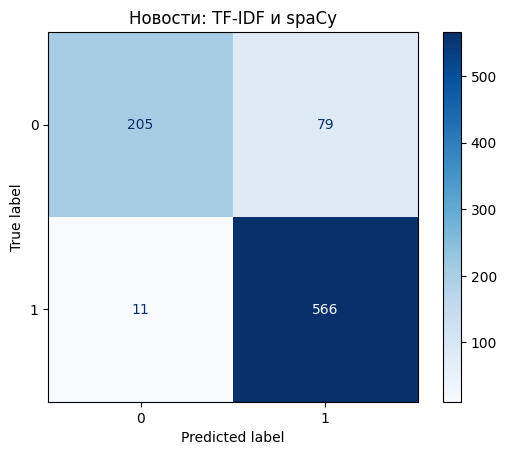

In [49]:
news_enriched = Pipeline([
    ('features', ColumnTransformer([
        ('text', clone(news_baseline.named_steps['tfidf']), 'text'),
        ('linguistic', MaxAbsScaler(), linguistic_columns)
    ], transformer_weights={'text': 1.0, 'linguistic': 0.3}, sparse_threshold=1.0)),
    ('model', clone(news_baseline.named_steps['model']))
])
news_enriched.fit(news_train_features, news_train['label'])
news_enriched_prediction = news_enriched.predict(news_test_features)
news_scores['TF-IDF + spaCy'] = classification_metrics(news_test['label'], news_enriched_prediction)
news_comparison = pd.DataFrame(news_scores).T
display(news_comparison)
print('Разница F1:', round(news_comparison.loc['TF-IDF + spaCy', 'F1 macro'] - news_comparison.loc['TF-IDF', 'F1 macro'], 4))
ConfusionMatrixDisplay.from_predictions(news_test['label'], news_enriched_prediction, cmap='Blues')
plt.title('Новости: TF-IDF и spaCy')
plt.show()